# Transformer-to-VLA

## Multimodal Transformer

### 可训练的 Mini Multimodal Transformer

---

**目标**

在受控图文任务上训练一个完整模型，并验证预测是否同时依赖图像和问题。

**核心概念**

- Vision Encoder
- Visual Projector
- Joint Self-Attention
- Question-Conditioned Readout
- Held-Out Evaluation
- Counterfactual Questions

**实现**

从零训练图像编码器、Projector、文本 Embedding、融合 Transformer 和三分类回答头，识别问题所指定的左／右方块颜色。

**学习重点**

用训练、独立测试和模态干预建立证据；该模型是合成问答分类器，不是 LLaVA 复现或自回归语言模型。


## 1. 环境

无需下载数据、权重或 tokenizer。默认自动使用 CUDA；CPU 可运行相同实验，耗时较长。


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)


PyTorch: 2.14.1+cu130 | Device: cuda


## 2. 数据设计：图像和文本都必须有用

每张图像有颜色不同的左右方块，颜色从 red / green / blue 中选择。每张图对应左右两个问题，答案必然不同；每种问题模板的三种答案严格均衡。背景噪声、亮度和位置有小幅变化。

- 只看文本的确定性分类器，在这个平衡评价集上的最高准确率是 $1/3$ 。
- 只看图像的确定性分类器，对同一图像的两个不同答案最多答对一个，最高准确率是 $1/2$ 。

这两个上界来自当前数据构造，不是所有图文任务的通用上界。训练、验证、测试按独立生成的场景划分，同一场景的两个问题始终在同一个集合中。测试仍使用相同颜色组合与生成规则，属于同分布测试，不是组合外推。

短问题为“left color”，长问题为“what color is the left square”等。小词表与模板只承担条件选择，不代表自然语言理解。


train scenes: 480 questions: 960 answer counts: [320, 320, 320]
validation scenes: 120 questions: 240 answer counts: [80, 80, 80]
test scenes: 240 questions: 480 answer counts: [160, 160, 160]


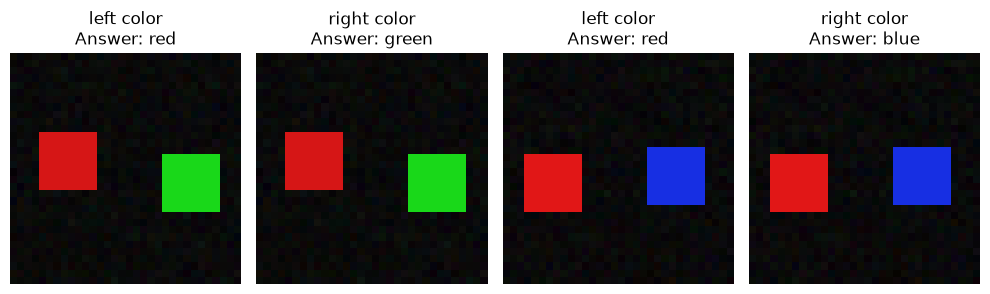

In [2]:
COLOR_NAMES = ["red", "green", "blue"]
PALETTE = torch.tensor([[0.95, 0.10, 0.10], [0.10, 0.85, 0.10], [0.10, 0.20, 0.95]])
VOCAB = {word: i for i, word in enumerate(
    ["<pad>", "what", "color", "is", "the", "left", "right", "square"])}
MAX_TEXT = 6
def question_tokens(side, template):
    word = ["left", "right"][side]
    words = [word, "color"] if template == 0 else ["what", "color", "is", "the", word, "square"]
    ids = [VOCAB[word] for word in words]
    return ids + [VOCAB["<pad>"]] * (MAX_TEXT - len(ids))

def make_dataset(scenes_per_pair, seed):
    assert scenes_per_pair % 2 == 0  # Balance both question templates exactly.
    rng = torch.Generator().manual_seed(seed)
    images, questions, answers = [], [], []
    for left in range(3):
        for right in range(3):
            if left == right:
                continue
            for repeat in range(scenes_per_pair):
                image = (0.04 + 0.015 * torch.randn(3, 32, 32, generator=rng)).clamp(0, 1)
                for side, color in enumerate([left, right]):
                    cx = (8 if side == 0 else 24) + int(torch.randint(-1, 2, (), generator=rng))
                    cy = 16 + int(torch.randint(-2, 3, (), generator=rng))
                    brightness = 0.8 + 0.2 * torch.rand((), generator=rng)
                    image[:, cy-4:cy+4, cx-4:cx+4] = (PALETTE[color] * brightness)[:, None, None]
                for side, answer in enumerate([left, right]):
                    images.append(image)
                    questions.append(question_tokens(side, repeat % 2))
                    answers.append(answer)
    return torch.stack(images), torch.tensor(questions), torch.tensor(answers)

train_data = make_dataset(80, SEED + 10)
val_data = make_dataset(20, SEED + 11)
test_data = make_dataset(40, SEED + 120)
for name, data in [("train", train_data), ("validation", val_data), ("test", test_data)]:
    imgs, questions, labels = data
    assert torch.equal(imgs[0::2], imgs[1::2])
    assert labels[0::2].ne(labels[1::2]).all()
    for question in questions.unique(dim=0):
        counts = labels[questions.eq(question).all(-1)].bincount(minlength=3)
        assert (counts == counts[0]).all()
    print(name, "scenes:", len(imgs) // 2, "questions:", len(labels),
          "answer counts:", labels.bincount(minlength=3).tolist())
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, index in zip(axes, [0, 1, 160, 161]):
    ax.imshow(train_data[0][index].permute(1, 2, 0))
    words = [word for idx in train_data[1][index].tolist() if idx
             for word, value in VOCAB.items() if value == idx]
    ax.set_title(" ".join(words) + "\nAnswer: " + COLOR_NAMES[train_data[2][index]])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Attention 与 Encoder Block

本节沿用上一节的手写 Attention。每个 Pre-LN Block 计算：

$$
U=X+\mathrm{Attention}(\mathrm{LN}(X)),\qquad
Y=U+\mathrm{FFN}(\mathrm{LN}(U)).
$$

视觉侧与融合侧都包含残差、LayerNorm 和 FFN；本实验不使用 Dropout，以便核对逐 Head 权重。Padding Mask 只限制 Key，可学习 Readout Token 始终有效。


In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        assert dim % heads == 0
        self.heads, self.head_dim = heads, dim // heads
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)

    def forward(self, query, key, value, key_padding_mask=None, attn_mask=None):
        batch, nq, dim = query.shape
        nk = key.size(1)
        assert key.shape == value.shape
        def split(x):
            return x.reshape(batch, -1, self.heads, self.head_dim).transpose(1, 2)
        q = split(self.q_proj(query))
        k = split(self.k_proj(key))
        v = split(self.v_proj(value))
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        blocked = torch.zeros(batch, 1, nq, nk, dtype=torch.bool, device=query.device)
        if attn_mask is not None:
            assert attn_mask.dtype == torch.bool and attn_mask.shape == (nq, nk)
            blocked = blocked | attn_mask[None, None]
        if key_padding_mask is not None:
            assert key_padding_mask.dtype == torch.bool
            assert key_padding_mask.shape == (batch, nk)
            blocked = blocked | key_padding_mask[:, None, None, :]
        if blocked.all(dim=-1).any():
            raise ValueError("Every query needs at least one visible key.")
        weights = scores.masked_fill(blocked, float("-inf")).softmax(dim=-1)
        context = (weights @ v).transpose(1, 2).contiguous().reshape(batch, nq, dim)
        return self.out_proj(context), weights


In [4]:
class EncoderBlock(nn.Module):
    def __init__(self, dim, heads=4, ff_dim=128):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.attn = MultiHeadAttention(dim, heads)
        self.ffn = nn.Sequential(nn.Linear(dim, ff_dim), nn.GELU(), nn.Linear(ff_dim, dim))

    def forward(self, x, key_padding_mask=None):
        normalized = self.norm1(x)
        update, weights = self.attn(normalized, normalized, normalized, key_padding_mask)
        x = x + update
        x = x + self.ffn(self.norm2(x))
        return x, weights


## 4. 完整的输入到输出路径

图像 $[B,3,32,32]$ → 16 个 Patch → 32 维视觉 Encoder → 48 维 Projector。文本最多 6 个词，经过 48 维 Embedding、文本位置与模态标记。Readout Token 用有效文本向量的均值加可学习偏置初始化，从第一次 Attention 开始就带有问题条件：

$$
z_{\mathrm{readout}}=r+\frac{1}{L_{\mathrm{valid}}}
\sum_{i\in\mathcal V}Z_{t,i}.
$$

 $r$ 是可学习向量， $\mathcal V$ 是非 Padding 文本位置集合。均值初始化本身不保留词序；带位置编码的完整文本序列仍参与后续融合。它与 ViT 中只使用共享可学习 CLS 初值的设计不同。拼接后：

$$
Z=[Z_v;Z_t;z_{\mathrm{readout}}]\in\mathbb R^{B\times23\times48}.
$$

两个融合 Block 使用双向 Self-Attention。最后读取 Readout 表示，输出三种颜色的 logits。监督答案不作为输入 Token，所以这里没有自回归目标泄漏问题，也没有文本生成。

位置编码区分左右网格与文本词序；视觉位置参数以标准差 0.2 初始化，随后随模型学习，这是本任务的配置，不是通用最优值。`drop_image` / `drop_text` 仅用于训练后的干预评价，不参与训练。移除文本时其有效数量为零，代码用 `clamp_min(1)` 避免除零，并只保留共享 Readout 偏置。


In [5]:
class MiniMultimodalTransformer(nn.Module):
    def __init__(self, vision_dim=32, model_dim=48, heads=4):
        super().__init__()
        self.patch = nn.Conv2d(3, vision_dim, kernel_size=8, stride=8)
        self.visual_position = nn.Parameter(torch.randn(1, 16, vision_dim) * 0.2)
        self.vision_block = EncoderBlock(vision_dim, heads)
        self.vision_norm = nn.LayerNorm(vision_dim)
        self.projector = nn.Linear(vision_dim, model_dim)
        self.text_embed = nn.Embedding(len(VOCAB), model_dim, padding_idx=VOCAB["<pad>"])
        self.text_position = nn.Parameter(torch.randn(1, MAX_TEXT, model_dim) * 0.02)
        self.modality = nn.Embedding(2, model_dim)
        nn.init.normal_(self.modality.weight, std=0.02)
        self.readout = nn.Parameter(torch.randn(1, 1, model_dim) * 0.02)
        self.fusion = nn.ModuleList([EncoderBlock(model_dim, heads) for _ in range(2)])
        self.final_norm = nn.LayerNorm(model_dim)
        self.head = nn.Linear(model_dim, len(COLOR_NAMES))

    def forward(self, images, text_ids, drop_image=False, drop_text=False, return_attention=False):
        visual = self.patch(images).flatten(2).transpose(1, 2) + self.visual_position
        visual, _ = self.vision_block(visual)
        visual = self.projector(self.vision_norm(visual)) + self.modality.weight[0]
        text = self.text_embed(text_ids) + self.text_position + self.modality.weight[1]
        text_padding = text_ids.eq(VOCAB["<pad>"])
        if drop_image:
            visual = torch.zeros_like(visual)
        if drop_text:
            # Remove content and length cues together, not just word embeddings.
            text = torch.zeros_like(text)
            text_padding = torch.ones_like(text_padding)
        batch = len(images)
        valid_text = (~text_padding).unsqueeze(-1)
        question_summary = (text * valid_text).sum(1, keepdim=True) / valid_text.sum(1, keepdim=True).clamp_min(1)
        readout = self.readout + question_summary
        x = torch.cat([visual, text, readout], dim=1)
        padding = torch.cat([
            torch.zeros(batch, 16, dtype=torch.bool, device=x.device),
            text_padding,
            torch.zeros(batch, 1, dtype=torch.bool, device=x.device)
        ], dim=1)
        for block in self.fusion:
            x, weights = block(x, padding)
        logits = self.head(self.final_norm(x[:, -1]))
        return (logits, weights, padding) if return_attention else logits

model = MiniMultimodalTransformer().to(device)
with torch.no_grad():
    example_logits, example_weights, example_padding = model(
        train_data[0][:4].to(device), train_data[1][:4].to(device), return_attention=True)
assert example_logits.shape == (4, 3)
assert example_weights.shape == (4, 4, 23, 23)  # 16 visual + 6 text + 1 readout
assert example_weights.masked_select(example_padding[:, None, None, :]).eq(0).all()
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Logits:", tuple(example_logits.shape), "last-layer attention:", tuple(example_weights.shape))


Parameters: 66227
Logits: (4, 3) last-layer attention: (4, 4, 23, 23)


## 5. 训练与验证

优化三分类 Cross-Entropy：

$$
L=-\frac{1}{B}\sum_{i=1}^{B}\log p_\theta(y_i\mid I_i,q_i).
$$

 $I_i$ 是图像， $q_i$ 是问题， $y_i$ 是颜色标签。模型配置在验证集上检查；以下固定训练 20 个 epoch，使用最终权重。独立测试场景使用 seed 162，不参与训练或 checkpoint 选择，不保存或加载外部 checkpoint。


Epoch  5/20 | train loss=0.0071 | validation accuracy=1.0000


Epoch 10/20 | train loss=0.0024 | validation accuracy=1.0000


Epoch 15/20 | train loss=0.0014 | validation accuracy=1.0000


Epoch 20/20 | train loss=0.0009 | validation accuracy=1.0000


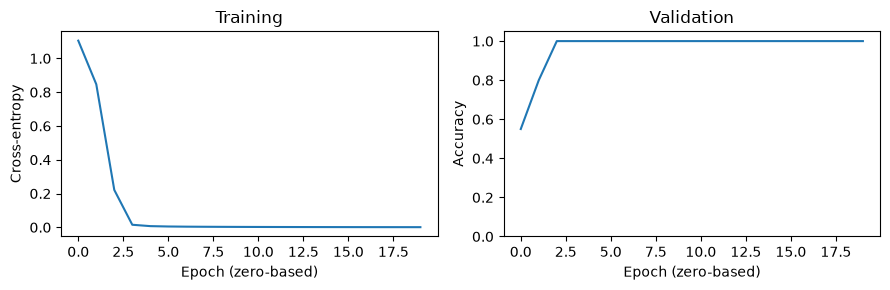

In [6]:
@torch.no_grad()
def evaluate(data, drop_image=False, drop_text=False):
    model.eval()
    images, questions, labels = data
    predictions, loss_sum = [], 0.0
    for start in range(0, len(labels), 128):
        x = images[start:start+128].to(device)
        q = questions[start:start+128].to(device)
        y = labels[start:start+128].to(device)
        logits = model(x, q, drop_image=drop_image, drop_text=drop_text)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        predictions.append(logits.argmax(-1).cpu())
    predictions = torch.cat(predictions)
    return {"loss": loss_sum / len(labels),
            "accuracy": predictions.eq(labels).float().mean().item()}, predictions

EPOCHS, BATCH_SIZE, LEARNING_RATE = 20, 64, 2e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-3)
order_rng = torch.Generator().manual_seed(SEED + 20)
history = {"train_loss": [], "val_accuracy": []}
for epoch in range(EPOCHS):
    model.train()
    order = torch.randperm(len(train_data[2]), generator=order_rng)
    loss_sum = 0.0
    for indices in order.split(BATCH_SIZE):
        images, questions, labels = [part[indices].to(device) for part in train_data]
        loss = F.cross_entropy(model(images, questions), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(indices)
    val_metrics, _ = evaluate(val_data)
    history["train_loss"].append(loss_sum / len(order))
    history["val_accuracy"].append(val_metrics["accuracy"])
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS} | train loss={history['train_loss'][-1]:.4f}"
              f" | validation accuracy={val_metrics['accuracy']:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(history["train_loss"])
axes[0].set(xlabel="Epoch (zero-based)", ylabel="Cross-entropy", title="Training")
axes[1].plot(history["val_accuracy"])
axes[1].set(xlabel="Epoch (zero-based)", ylabel="Accuracy", ylim=(0, 1.05), title="Validation")
plt.tight_layout()
plt.show()


## 6. 独立测试与模态干预

完整输入测试使用 240 个新场景、480 个问题。随后在同一模型上移除一种模态，或打乱图像与问题的对应关系。打乱实验保留原标签，用于观察原任务准确率变化；它不是对改变后图像的新正确答案进行评价。

移除模态会造成训练分布外的输入，因此下降幅度不是模态贡献的精确百分比。结合数据的单模态上界和下一节具有正确反事实标签的问题切换，才能更有依据地判断是否使用了两种输入。


Full input             accuracy=1.0000 | loss=0.0009
No visual features     accuracy=0.3333 | loss=3.1776
No text                accuracy=0.4667 | loss=3.6857
Shuffled images        accuracy=0.3646 | loss=4.9602
Shuffled questions     accuracy=0.4875 | loss=3.9588


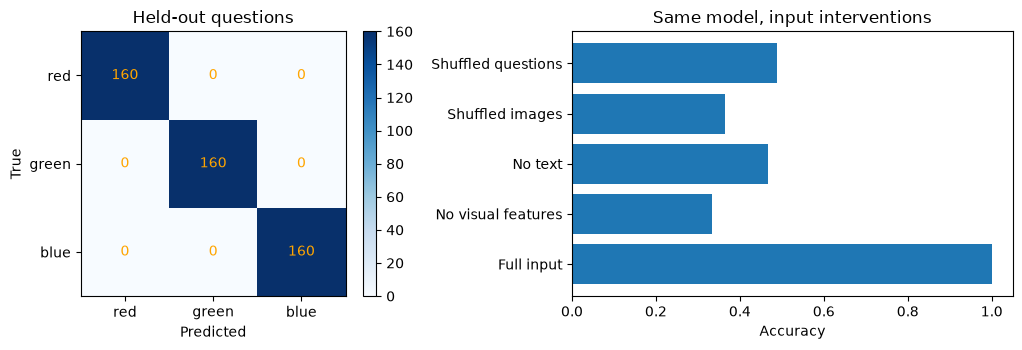

In [7]:
test_metrics, test_predictions = evaluate(test_data)
without_image, _ = evaluate(test_data, drop_image=True)
without_text, _ = evaluate(test_data, drop_text=True)
permutation = torch.randperm(len(test_data[2]), generator=torch.Generator().manual_seed(SEED + 30))
shuffled_images, _ = evaluate((test_data[0][permutation], test_data[1], test_data[2]))
shuffled_questions, _ = evaluate((test_data[0], test_data[1][permutation], test_data[2]))
evaluation = {
    "Full input": test_metrics, "No visual features": without_image, "No text": without_text,
    "Shuffled images": shuffled_images, "Shuffled questions": shuffled_questions,
}
for name, metrics in evaluation.items():
    print(f"{name:22s} accuracy={metrics['accuracy']:.4f} | loss={metrics['loss']:.4f}")
confusion = torch.bincount(test_data[2] * 3 + test_predictions, minlength=9).reshape(3, 3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
im = axes[0].imshow(confusion, cmap="Blues")
axes[0].set(xticks=range(3), yticks=range(3), xticklabels=COLOR_NAMES,
            yticklabels=COLOR_NAMES, xlabel="Predicted", ylabel="True", title="Held-out questions")
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, str(confusion[i, j].item()), ha="center", va="center", color="orange")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
axes[1].barh(list(evaluation), [row["accuracy"] for row in evaluation.values()])
axes[1].set(xlim=(0, 1.05), xlabel="Accuracy", title="Same model, input interventions")
plt.tight_layout()
plt.show()


## 7. 同一图像切换问题：答案是否正确地改变？

每张测试图的左右问题成对排列。交换问题后，正确答案也交换；这里使用交换后的真实标签重新评价，而非只检查输出有没有变化。由于左右颜色不同，正确模型应改变预测并回答另一侧颜色。

该检查复用原测试集中已有的问答组合，交换后的准确率是原测试的重排，不能计作额外的独立泛化证据；答案改变率需结合正确率解释。


Question-switch accuracy with new labels: 1.0
Answer change rate: 1.0


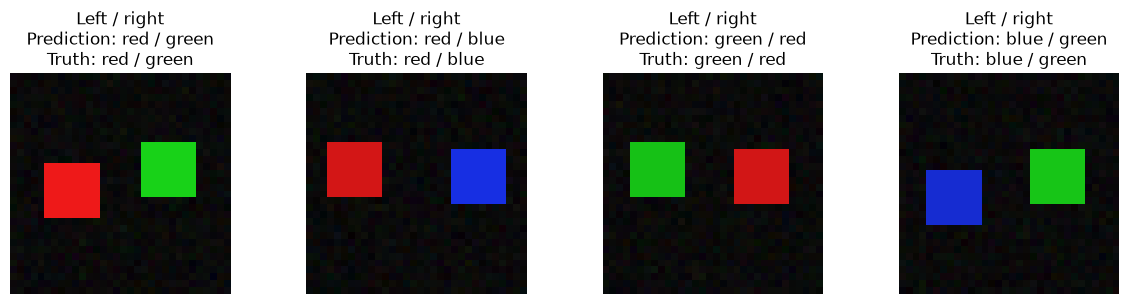

In [8]:
swap = torch.arange(len(test_data[2])).reshape(-1, 2).flip(1).flatten()
counterfactual_metrics, counterfactual_predictions = evaluate(
    (test_data[0], test_data[1][swap], test_data[2][swap]))
answer_change_rate = counterfactual_predictions.ne(test_predictions).float().mean().item()
print("Question-switch accuracy with new labels:", counterfactual_metrics["accuracy"])
print("Answer change rate:", answer_change_rate)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, scene in zip(axes, [0, 50, 100, 200]):
    index = 2 * scene
    ax.imshow(test_data[0][index].permute(1, 2, 0))
    predicted = [COLOR_NAMES[i] for i in test_predictions[index:index+2].tolist()]
    actual = [COLOR_NAMES[i] for i in test_data[2][index:index+2].tolist()]
    ax.set_title(f"Left / right\nPrediction: {' / '.join(predicted)}\nTruth: {' / '.join(actual)}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. 逐 Head 检查 Readout → Visual Attention

展示最后一层 Readout 对 16 个视觉 Key 的权重；它还可关注文本和自己，因此视觉子块的行和不必为 1。每个 Head 独立 colorbar，颜色相似不表示权重相同。热力图只描述本次权重分配，不能替代前面的测试与干预。


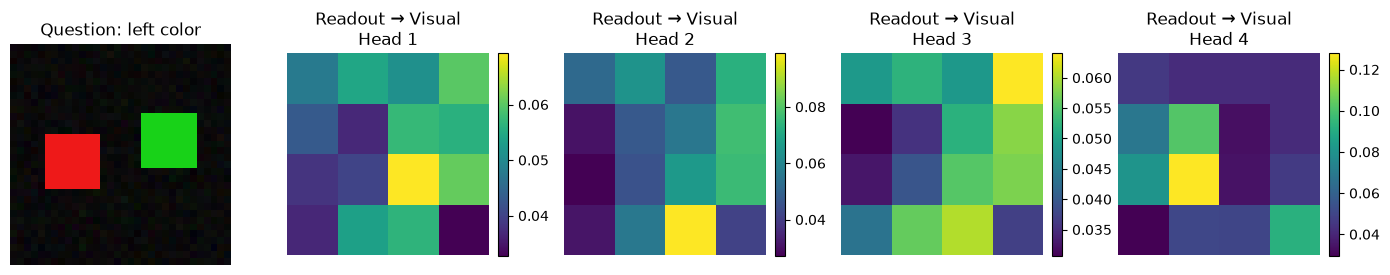

Visual-key mass per head: [0.7944408059120178, 0.8888524770736694, 0.771746039390564, 0.9279531836509705]


In [9]:
model.eval()
with torch.no_grad():
    _, weights, padding = model(test_data[0][:1].to(device), test_data[1][:1].to(device),
                                return_attention=True)
    assert weights.masked_select(padding[:, None, None, :]).eq(0).all()
    visual_weights = weights[0, :, -1, :16].reshape(4, 4, 4).cpu()
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(test_data[0][0].permute(1, 2, 0))
axes[0].set_title("Question: left color")
axes[0].axis("off")
for head in range(4):
    data = visual_weights[head].numpy()
    im = axes[head+1].imshow(data, cmap="viridis", vmin=data.min(), vmax=data.max())
    axes[head+1].set_title(f"Readout → Visual\nHead {head+1}")
    axes[head+1].axis("off")
    fig.colorbar(im, ax=axes[head+1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
print("Visual-key mass per head:", visual_weights.flatten(1).sum(-1).tolist())
assert all(math.isfinite(value) for row in evaluation.values() for value in row.values())


## 9. 已验证范围与后续连接

本实验将图像编码、可训练投影、文本输入与融合 Transformer 接到同一个监督任务。结果只适用于当前三种颜色、两种模板和合成场景；尚未验证自然图像、开放词汇、自由语言生成、真实机器人动作或多随机种子稳定性。

第五章学习 DDPM / Flow Matching 如何生成连续片段；将这里的多模态表示用作动作生成条件还需要匹配的数据与联合训练，不是简单替换最后一层即可完成。

- 增加同色方块或新问题模板时，重新计算单模态基线，不沿用本节的上界。
- 用相同数据与预算比较 Cross-Attention 融合，区分架构选择与参数量差异。
- 在多个随机种子、不同背景或未见布局上测试，再讨论泛化。

[项目首页](../README.md) · [上一节](03_Cross_Attention_and_Fusion.ipynb) · [下一章：Diffusion / Flow](../05_Diffusion_and_Flow_Models/01_DDPM_Fundamentals/01_2D_Ring.ipynb) · [知识库](../KNOWLEDGE_BASE.md#part-ii)
